# Stage 2 — in-house fine-tuning

Stage 2 starts from the Stage 1 pre-trained checkpoint `best_model_fixed.weights.h5`. It ranks all 80 in-house images with that checkpoint first, then lets the user define a validated 10/60 or 20/60 experiment. The training model is separate: `train()` performs its one strict checkpoint load.

**Selection warning.** Choosing only the worst-ranked images for training and the easiest images for validation would bias the result. Prefer difficulty-stratified selection across the ranking. Any split informed by this ranking is model-guided and its validation result is **not an independent test evaluation**; the 60 images are used for selection and model control.


In [1]:
import os
import sys
from pathlib import Path


def find_repo_root():
    starts = [Path.cwd().resolve(), Path('/kaggle/working').resolve()]
    for start in starts:
        for candidate in (start, *start.parents):
            if (candidate / 'src' / 'config.py').is_file():
                return candidate
    for search_root in (Path('/kaggle/working'), Path('/kaggle/input')):
        if search_root.is_dir():
            matches = sorted(search_root.rglob('src/config.py'))
            if matches:
                return matches[0].parent.parent
    raise FileNotFoundError('Could not locate repository root containing src/config.py')


def resolve_pretrained_checkpoint(repo_root):
    env_path = os.getenv('CEPHALO_PRETRAINED_WEIGHTS')
    candidates = [Path(env_path).expanduser()] if env_path else []
    candidates += [
        repo_root / 'checkpoints' / 'best_model_fixed.weights.h5',
        Path('/kaggle/input/models/pouyansajadi78/pretrain-weights-oct2/tensorflow2/default/1/best_model_fixed.weights.h5'),
        Path('/kaggle/working/best_model_fixed.weights.h5'),
    ]
    for search_root in (Path('/kaggle/input'), Path('/kaggle/working')):
        if search_root.is_dir():
            candidates.extend(sorted(search_root.rglob('best_model_fixed.weights.h5')))
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate not in seen and candidate.is_file():
            return str(candidate)
        seen.add(candidate)
    raise FileNotFoundError(
        'best_model_fixed.weights.h5 was not found. Set CEPHALO_PRETRAINED_WEIGHTS '
        'or attach/copy the Stage 1 pre-trained checkpoint.'
    )

REPO_ROOT = Path('/kaggle/input/models/pouyansajadi78/model-oct-2-v1/tensorflow2/default/1')
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from config import make_stage2_finetune_config, resolve_data_dir
from reproducibility import set_global_seed

FT_ROOT = os.getenv('CEPHALO_FT_ROOT', '/kaggle/input/datasets/pouyansajadi78/fine-tuning-dataset-final') if Path('/kaggle').is_dir() else str(REPO_ROOT / 'data' / 'inhouse')
PRETRAINED_WEIGHTS = resolve_pretrained_checkpoint(REPO_ROOT)
RESULTS_DIR = Path('/kaggle/working/results') if Path('/kaggle').is_dir() else REPO_ROOT / 'results'
LOG_DIR = Path(os.getenv('CEPHALO_LOG_DIR', str(RESULTS_DIR)))
CHECKPOINT_DIR = Path(os.getenv('CEPHALO_CHECKPOINT_DIR', '/kaggle/working/checkpoints' if Path('/kaggle').is_dir() else str(REPO_ROOT / 'checkpoints')))
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

if Path('/kaggle').is_dir():
    FT_IMAGES = resolve_data_dir(FT_ROOT, Path('images_v2') / 'images_v2')
    FT_ANNOTATIONS = resolve_data_dir(FT_ROOT, Path('annotations_v2') / 'annotations_v2')
else:
    FT_IMAGES = str(Path(FT_ROOT) / 'images')
    FT_ANNOTATIONS = str(Path(FT_ROOT) / 'annotations')

ranking_cfg = make_stage2_finetune_config(
    ft_root=FT_ROOT, pretrained_weights=PRETRAINED_WEIGHTS,
    log_dir=str(LOG_DIR), checkpoint_dir=str(CHECKPOINT_DIR),
    backbone_weights=None,
)
set_global_seed(ranking_cfg.seed)  # before ranking model/data construction
#assert Path(PRETRAINED_WEIGHTS).name == 'best_model_fixed.weights.h5'
print('Repository:', REPO_ROOT)
print('In-house images:', FT_IMAGES)
print('Pre-trained checkpoint:', PRETRAINED_WEIGHTS)


Repository: /kaggle/input/models/pouyansajadi78/model-oct-2-v1/tensorflow2/default/1
In-house images: /kaggle/input/datasets/pouyansajadi78/fine-tuning-dataset-final/images_v2/images_v2
Pre-trained checkpoint: /kaggle/input/models/pouyansajadi78/pretrain-weights-oct2/tensorflow2/default/1/best_model_fixed.weights.h5


## 1. Pre-training audit: rank all 80 images with Stage 2

Each image is evaluated individually (`batch_size=1`), without augmentation and with `training=False`. Rank 1 is worst by 19-landmark image MRE; ties use image ID for deterministic ordering. The table also records maximum landmark error and image-level SDR.


In [2]:
from evaluate import load_compatible_weights, rank_inhouse_images
from model import build_model

ranking_model, _ = build_model(ranking_cfg)
load_compatible_weights(ranking_model, PRETRAINED_WEIGHTS, ranking_cfg)  # strict, ranking model only
RANKING_CSV = RESULTS_DIR / 'pretrained_all80_image_ranking.csv'
ranking_table = rank_inhouse_images(
    ranking_model, ranking_cfg, image_ids=range(1, 81),
    root=FT_ROOT, image_dir=FT_IMAGES, annotation_dir=FT_ANNOTATIONS,
    csv_path=RANKING_CSV,
)
display(ranking_table)
print('Saved:', RANKING_CSV)
del ranking_model  # training below builds a fresh model; no duplicate load into it


I0000 00:00:1792360315.751878      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792360315.755223      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


,rank_worst_to_best,image_id,mre_mm,max_landmark_error_mm,sdr_2_0mm_percent,sdr_2_5mm_percent,sdr_3_0mm_percent,sdr_4_0mm_percent
0,1,25,8.144407,58.224319,31.578947,42.105263,52.631579,63.157895
1,2,24,5.843822,32.429364,42.105263,47.368421,57.894737,68.421053
2,3,71,4.845299,33.531828,36.842105,36.842105,36.842105,63.157895
3,4,56,4.165464,31.683132,68.421053,73.684211,78.947368,84.210526
4,5,80,4.159614,15.592522,31.578947,42.105263,47.368421,68.421053
...,...,...,...,...,...,...,...,...
75,76,64,2.115858,6.717268,52.631579,57.894737,73.684211,89.473684
76,77,65,2.105550,5.095523,42.105263,63.157895,68.421053,89.473684
77,78,12,2.019014,3.978698,47.368421,63.157895,78.947368,100.000000
78,79,44,1.935591,5.519111,68.421053,68.421053,68.421053,89.473684


Saved: /kaggle/working/results/pretrained_all80_image_ranking.csv


## 2. Manual split and experiment configuration

Edit the next cell after inspecting the ranking. The provided constants remain convenient references, not hard-wired choices. For `n10`, provide ten IDs nested within `REFERENCE_TRAIN20`; the other ten IDs outside the fixed 60 validation set are explicitly reported as unused. Use `head_logits` for the more conservative 10-image scope if desired.


In [3]:
from config import (
    FINETUNE_TRAIN_IDS, FINETUNE_VAL_IDS, make_finetune_experiment_config,
    validate_finetune_split,
)

# USER-CONTROLLED VALUES — edit these lists/name/scope.
#TRAIN_IMAGE_IDS = list(FINETUNE_TRAIN_IDS)  # enter 10 or 20 unique IDs
TRAIN_IMAGE_IDS = [
    25, 76, 80, 71, 46, 24, 41, 72, 31, 16,
    42, 15, 22, 69, 33, 38, 5, 50, 9, 47
]
#VAL_IMAGE_IDS = list(FINETUNE_VAL_IDS)      # enter the fixed 60 unique IDs
VAL_IMAGE_IDS = [
    23, 74, 78, 3, 11, 7, 32, 26, 27, 34,
    14, 62, 36, 20, 21, 6, 40, 10, 8, 19,
    39, 18, 30, 4, 60, 28, 2, 55, 49, 37,
    35, 51, 68, 13, 59, 70, 17, 63, 73, 48,
    77, 1, 61, 75, 66, 45, 79, 43, 58, 67,
    53, 64, 56, 52, 29, 54, 57, 65, 12, 44
]
INHOUSE_IMAGE_RESOLUTION = 0.08  # mm/pixel for the in-house dataset (ISBI = 0.10)
EXPERIMENT_NAME = 'finetune_n20'
TRAINABLE_SCOPE = 'dec2_head_logits'      # optional: 'head_logits'
REFERENCE_TRAIN20 = list(FINETUNE_TRAIN_IDS)  # enforces nesting for an n10 experiment

split = validate_finetune_split(
    TRAIN_IMAGE_IDS, VAL_IMAGE_IDS,
    reference_train20=REFERENCE_TRAIN20 if len(TRAIN_IMAGE_IDS) == 10 else None,
)
cfg = make_finetune_experiment_config(
    TRAIN_IMAGE_IDS, VAL_IMAGE_IDS,
    epochs = 50,
    experiment_name=EXPERIMENT_NAME,
    trainable_scope=TRAINABLE_SCOPE,
    reference_train20=REFERENCE_TRAIN20 if len(TRAIN_IMAGE_IDS) == 10 else None,
    ft_root=FT_ROOT, pretrained_weights=PRETRAINED_WEIGHTS,
    image_resolution=INHOUSE_IMAGE_RESOLUTION,
    log_dir=str(LOG_DIR), checkpoint_dir=str(CHECKPOINT_DIR),
    backbone_weights=None,
)
set_global_seed(cfg.seed)  # before final loader/model construction
print('Experiment:', cfg.experiment_name, '| training n =', split['sample_count'])
print('Train IDs:', split['train_ids'])
print('Validation IDs:', split['val_ids'])
print('Unused IDs:', split['unused_ids'])
print('In-house image resolution: {:.2f} mm/pixel'.format(cfg.image_resolution))
print('Scope:', cfg.trainable_scope)
print('Best-loss checkpoint:', CHECKPOINT_DIR / cfg.output_filename)
print('Best-MRE checkpoint:', CHECKPOINT_DIR / cfg.best_mre_output_filename)

assert cfg.epochs == 50 and cfg.learning_rate == 5e-6 and cfg.weight_decay == 5e-5
assert cfg.decoder_dropout_rate == 0.20 and cfg.checkpoint_monitor == 'val_loss'
assert cfg.lr_scheduler_monitor == cfg.early_stopping_monitor == 'val_loss'
assert cfg.lr_plateau_patience == 2 and cfg.early_stopping_patience == 5
assert cfg.lr_plateau_min_delta == cfg.early_stopping_min_delta == 2e-4
assert cfg.image_resolution == INHOUSE_IMAGE_RESOLUTION
assert cfg.encoder_mode == 'stage1' and cfg.freeze_encoder_batch_norm


Experiment: finetune_n20 | training n = 20
Train IDs: (25, 76, 80, 71, 46, 24, 41, 72, 31, 16, 42, 15, 22, 69, 33, 38, 5, 50, 9, 47)
Validation IDs: (23, 74, 78, 3, 11, 7, 32, 26, 27, 34, 14, 62, 36, 20, 21, 6, 40, 10, 8, 19, 39, 18, 30, 4, 60, 28, 2, 55, 49, 37, 35, 51, 68, 13, 59, 70, 17, 63, 73, 48, 77, 1, 61, 75, 66, 45, 79, 43, 58, 67, 53, 64, 56, 52, 29, 54, 57, 65, 12, 44)
Unused IDs: ()
In-house image resolution: 0.08 mm/pixel
Scope: dec2_head_logits
Best-loss checkpoint: /kaggle/working/checkpoints/best_model_finetune_v3_finetune_n20_best_loss.weights.h5
Best-MRE checkpoint: /kaggle/working/checkpoints/best_model_finetune_v3_finetune_n20_best_mre.weights.h5


## 3. Separate loaders and fresh training model

`train_loader` provides augmented online metrics. `train_eval_loader` evaluates the same IDs without augmentation, without shuffling, and in inference mode after each epoch. Validation is also unaugmented. The fresh training model is **not** manually loaded here; `train()` owns exactly one strict Stage 2 load.


In [4]:
import tensorflow as tf
from data import InHouseDataset
from model import build_model
from train import train

train_loader = InHouseDataset(
    FT_ROOT, TRAIN_IMAGE_IDS, cfg, training=True, shuffle=True,
    image_dir=FT_IMAGES, annotation_dir=FT_ANNOTATIONS,
)
train_eval_loader = InHouseDataset(
    FT_ROOT, TRAIN_IMAGE_IDS, cfg, training=False, shuffle=False,
    image_dir=FT_IMAGES, annotation_dir=FT_ANNOTATIONS,
)
val_loader = InHouseDataset(
    FT_ROOT, VAL_IMAGE_IDS, cfg, training=False, shuffle=False,
    image_dir=FT_IMAGES, annotation_dir=FT_ANNOTATIONS,
)
model, encoder_layer_names = build_model(cfg)
# No load_weights call: train() performs the training model's sole strict load.
print('Complete batches — online:', len(train_loader), 'train eval:', len(train_eval_loader), 'validation:', len(val_loader))
print('Model outputs:', model.output_shape)
print('Dropout layers have no weights:', {
    layer.name: len(layer.weights) for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dropout)
})


Complete batches — online: 10 train eval: 10 validation: 30
Model outputs: [(None, 19, 2), (None, 128, 104, 19)]
Dropout layers have no weights: {'dec4_drop': 0, 'dec3_drop': 0, 'dec2_drop': 0}


In [5]:
history = train(
    cfg,
    train_loader=train_loader,
    train_eval_loader=train_eval_loader,
    val_loader=val_loader,
    model=model,
    encoder_layer_names=encoder_layer_names,
)
assert history['incoming_checkpoint'] == cfg.pretrained_weights
print('Parameter counts:', history['parameter_counts'])
print('Best validation loss:', history['best_loss_value'], 'at epoch', history['best_loss_epoch'])
print('Best validation MRE:', history['best_mre_value'], 'at epoch', history['best_mre_epoch'])
print('Stop:', history['stop_reason'], 'at epoch', history['stopped_epoch'])
print('Restored best-loss evaluation:', history['restored_final_validation'])
print('Checkpoints:', history['checkpoint_paths'])
print('History:', history['history_path'])


Parameters — trainable: 2,509,139; non-trainable: 70,779,776; total: 73,288,915
Epoch 0 stage2_finetune_v3 baseline — val loss: 0.10661; val MRE: 2.62 mm

Epoch 1/50
----------------------------------------
  Train online — loss 0.18924 | MRE 4.07 mm
  Train eval   — loss 0.16002 | MRE 3.53 mm
  Validation   — loss 0.09854 | MRE 2.48 mm | SDR@2 51.4% | SDR@2.5 61.5% | SDR@3 71.3% | SDR@4 84.8%
  New best MRE 2.482 mm — saved /kaggle/working/checkpoints/best_model_finetune_v3_finetune_n20_best_mre.weights.h5
  New best val_loss 0.0985395 — saved /kaggle/working/checkpoints/best_model_finetune_v3_finetune_n20_best_loss.weights.h5

Epoch 2/50
----------------------------------------
  Train online — loss 0.17449 | MRE 3.80 mm
  Train eval   — loss 0.14839 | MRE 3.32 mm
  Validation   — loss 0.09198 | MRE 2.37 mm | SDR@2 54.1% | SDR@2.5 63.9% | SDR@3 73.0% | SDR@4 85.9%
  New best MRE 2.372 mm — saved /kaggle/working/checkpoints/best_model_finetune_v3_finetune_n20_best_mre.weights.h5
  New

## 4. Honest learning curves

Raw validation loss is never replaced or smoothed. Its running minimum is shown only as a separately labelled selection trace. Epoch zero is the loaded Stage 2 baseline. Unaugmented inference-mode train evaluation is the primary train/validation comparison; augmented online loss is shown separately.


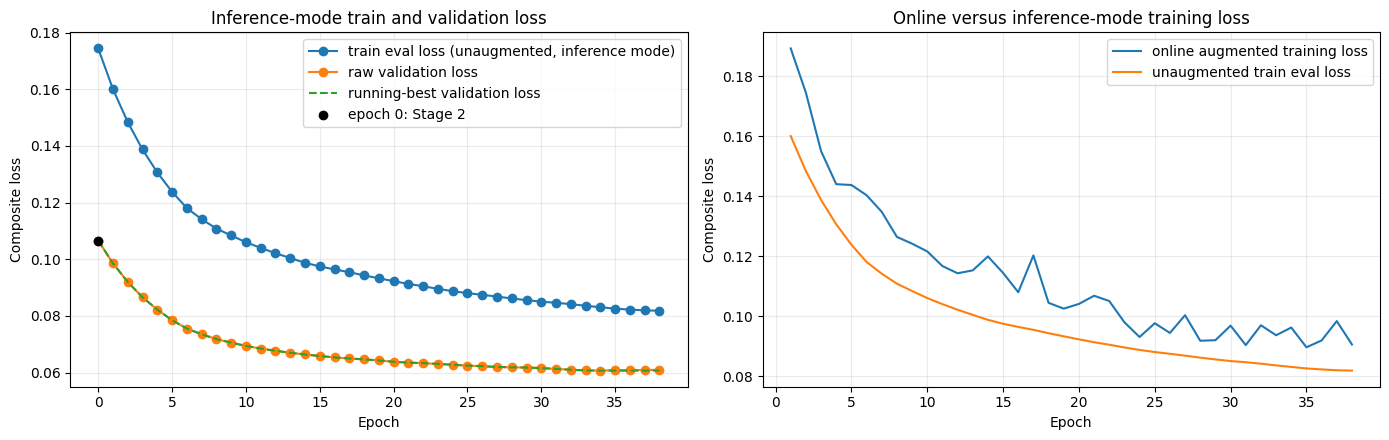

In [6]:
import matplotlib.pyplot as plt

epochs = [0] + history['epoch']
train_eval_loss = [history['train_eval_baseline']['loss']] + history['train_eval_loss']
val_loss = [history['baseline']['loss']] + history['val_loss']
running_best = [history['baseline']['loss']] + history['val_loss_running_best']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(epochs, train_eval_loss, marker='o', label='train eval loss (unaugmented, inference mode)')
axes[0].plot(epochs, val_loss, marker='o', label='raw validation loss')
axes[0].plot(epochs, running_best, linestyle='--', label='running-best validation loss')
axes[0].scatter([0], [val_loss[0]], color='black', zorder=5, label='epoch 0: Stage 2')
axes[0].set(xlabel='Epoch', ylabel='Composite loss', title='Inference-mode train and validation loss')
axes[0].legend(); axes[0].grid(alpha=0.25)

axes[1].plot(history['epoch'], history['train_online_loss'], label='online augmented training loss')
axes[1].plot(history['epoch'], history['train_eval_loss'], label='unaugmented train eval loss')
axes[1].set(xlabel='Epoch', ylabel='Composite loss', title='Online versus inference-mode training loss')
axes[1].legend(); axes[1].grid(alpha=0.25)
plt.tight_layout(); plt.show()


## 5. Primary restored result and optional best-MRE comparison

The in-memory `model` is restored to the **lowest-validation-loss** checkpoint. Subsequent per-landmark analysis should use it. A separately constructed model can strictly load the best-MRE checkpoint for a clearly labelled comparison; never conflate the two outcomes.


In [7]:
from train import evaluate
from evaluate import load_compatible_weights

primary_metrics = evaluate(model, val_loader, cfg)
print('PRIMARY restored best-loss result')
print('MRE:', primary_metrics['mre'], '| SDR:', primary_metrics['sdr'])
print('Per-landmark MRE:', primary_metrics['per_landmark_mre'])

best_mre_model, _ = build_model(cfg)
load_compatible_weights(best_mre_model, history['checkpoint_paths']['best_mre'], cfg)
best_mre_metrics = evaluate(best_mre_model, val_loader, cfg)
print()
print('SEPARATE best-MRE checkpoint result')
print('MRE:', best_mre_metrics['mre'], '| SDR:', best_mre_metrics['sdr'])


PRIMARY restored best-loss result
MRE: 1.8194074630737305 | SDR: {2.0: 64.82456140350877, 2.5: 76.57894736842105, 3.0: 83.77192982456141, 4.0: 92.98245614035088}
Per-landmark MRE: [1.3500344  2.4935956  2.477652   2.960671   2.3401675  2.4762297
 1.234006   1.1804265  0.8853539  2.4057329  1.2762803  0.96509415
 1.0655762  1.2566414  1.8631536  1.9785355  1.8971347  2.2421792
 2.2202768 ]

SEPARATE best-MRE checkpoint result
MRE: 1.8194074630737305 | SDR: {2.0: 64.82456140350877, 2.5: 76.57894736842105, 3.0: 83.77192982456141, 4.0: 92.98245614035088}


### Interpretation boundary

These are validation/model-selection results. Ranking all 80 images before choosing the split, repeatedly monitoring the 60 validation images, and selecting checkpoints from them means this workflow does not provide an independent test estimate. Preserve the exact split IDs, unused IDs, ranking CSV, history JSON, and both checkpoints with any reported result.


## 6. Comprehensive validation results for the fixed n20 experiment

The following cells use the already restored **primary best-validation-loss model** in `model`. They do not retrain or change the 20-image experiment. They collect one unaugmented, inference-mode prediction per validation image, retain the predicted heatmaps, calculate image- and landmark-level errors, and export paper-ready tables and figures.

**Interpretation boundary:** these are validation/model-selection results, not an independent test estimate. Ranking all 80 images informed split selection, the 60-image validation set was monitored repeatedly, and checkpoints were selected using it. Do not call this an independent test unless the data provenance is separately confirmed to establish that it was never used for model selection. This notebook retains its existing split and selection process.

**Resolution caveat:** this notebook configures `cfg.image_resolution` as 0.08 mm/pixel, while the available fine-tuning log records 0.10 mm/pixel. The cells below retain the notebook's configured conversion for reproducibility but explicitly flag that discrepancy. Do not interpret mm errors or millimetre thresholds clinically until the source resolution is verified; pixel-coordinate errors remain available independently.


In [8]:
# Collect raw images, raw annotations, predictions, heatmaps, and paper-scale errors.
# This is inference only: no optimizer, augmentation, or checkpoint selection is used here.
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from data import preprocess, read_points, read_rgb

LANDMARK_NAMES = [
    cfg.anatomical_landmarks.get(str(i), f'Landmark {i + 1}')
    for i in range(cfg.num_landmarks)
]
REFERENCE_SCALE = np.array([cfg.original_width, cfg.original_height], dtype=np.float32)
RESULTS_STEM = f'stage3_v3_{EXPERIMENT_NAME}'


def _image_and_annotation_paths(image_id):
    image_path = Path(FT_IMAGES) / f'({int(image_id)}).tif'
    annotation_path = Path(FT_ANNOTATIONS) / f'({int(image_id)}).txt'
    if not image_path.exists():
        matches = sorted(Path(FT_IMAGES).glob(f'*{int(image_id)}*'))
        if not matches:
            raise FileNotFoundError(f'No image found for image ID {image_id}')
        image_path = matches[0]
    if not annotation_path.exists():
        matches = sorted(Path(FT_ANNOTATIONS).glob(f'*{int(image_id)}*'))
        if not matches:
            raise FileNotFoundError(f'No annotation found for image ID {image_id}')
        annotation_path = matches[0]
    return image_path, annotation_path


records = []
for image_id in sorted(VAL_IMAGE_IDS):
    image_path, annotation_path = _image_and_annotation_paths(image_id)
    raw_image = read_rgb(image_path)
    raw_truth = read_points(annotation_path, cfg)
    model_image, truth_norm = preprocess(raw_image, raw_truth, cfg, augmentation=None)
    outputs = model(np.expand_dims(model_image, axis=0), training=False)
    pred_norm = np.asarray(outputs['coords'])[0].astype(np.float32)
    heatmaps = np.asarray(outputs['heatmaps'])[0].astype(np.float32)

    pred_reference = pred_norm * REFERENCE_SCALE
    truth_reference = truth_norm * REFERENCE_SCALE
    reference_delta = pred_reference - truth_reference
    error_px_reference = np.linalg.norm(reference_delta, axis=-1)
    error_mm = error_px_reference * cfg.image_resolution
    raw_scale = np.array([raw_image.shape[1], raw_image.shape[0]], dtype=np.float32)
    pred_raw = pred_norm * raw_scale

    records.append({
        'image_id': int(image_id),
        'image_path': str(image_path),
        'annotation_path': str(annotation_path),
        'image': raw_image,
        'truth_raw': raw_truth,
        'truth_norm': truth_norm,
        'pred_norm': pred_norm,
        'pred_raw': pred_raw,
        'heatmaps': heatmaps,
        'error_mm': error_mm,
        'error_px_reference': error_px_reference,
        'pred_reference': pred_reference,
        'truth_reference': truth_reference,
        'mre_mm': float(np.mean(error_mm)),
        'median_landmark_error_mm': float(np.median(error_mm)),
        'std_landmark_error_mm': float(np.std(error_mm)),
        'max_landmark_error_mm': float(np.max(error_mm)),
        'worst_landmark_index': int(np.argmax(error_mm)),
    })

records_by_id = {record['image_id']: record for record in records}
records_sorted_best = sorted(records, key=lambda item: (item['mre_mm'], item['image_id']))
example_records = {
    'best': records_sorted_best[0],
    'median': records_sorted_best[len(records_sorted_best) // 2],
    'worst': records_sorted_best[-1],
}

thresholds = [float(value) for value in cfg.precision_thresholds]
per_image_rows = []
for record in records:
    row = {
        'image_id': record['image_id'],
        'mre_mm': record['mre_mm'],
        'median_landmark_error_mm': record['median_landmark_error_mm'],
        'std_landmark_error_mm': record['std_landmark_error_mm'],
        'max_landmark_error_mm': record['max_landmark_error_mm'],
        'worst_landmark_index': record['worst_landmark_index'] + 1,
        'worst_landmark': LANDMARK_NAMES[record['worst_landmark_index']],
    }
    for threshold in thresholds:
        label = str(threshold).replace('.', '_')
        row[f'sdr_{label}mm_percent'] = float(np.mean(record['error_mm'] < threshold) * 100.0)
    per_image_rows.append(row)

per_image_table = pd.DataFrame(per_image_rows).sort_values(
    ['mre_mm', 'image_id'], ascending=[False, True], kind='mergesort'
).reset_index(drop=True)
per_image_table.insert(0, 'rank_worst_to_best', np.arange(1, len(per_image_table) + 1))

landmark_rows = []
error_matrix = np.stack([record['error_mm'] for record in records], axis=0)
for landmark_index, landmark_name in enumerate(LANDMARK_NAMES):
    values = error_matrix[:, landmark_index]
    row = {
        'landmark_index': landmark_index + 1,
        'landmark': landmark_name,
        'mean_error_mm': float(np.mean(values)),
        'median_error_mm': float(np.median(values)),
        'std_error_mm': float(np.std(values)),
        'p25_error_mm': float(np.percentile(values, 25)),
        'p75_error_mm': float(np.percentile(values, 75)),
        'max_error_mm': float(np.max(values)),
    }
    for threshold in thresholds:
        label = str(threshold).replace('.', '_')
        row[f'sdr_{label}mm_percent'] = float(np.mean(values < threshold) * 100.0)
    landmark_rows.append(row)
landmark_table = pd.DataFrame(landmark_rows)

selected_landmark_table = pd.DataFrame([
    {
        'example': label,
        'image_id': record['image_id'],
        'landmark_index': index + 1,
        'landmark': LANDMARK_NAMES[index],
        'error_mm': float(record['error_mm'][index]),
    }
    for label, record in example_records.items()
    for index in range(cfg.num_landmarks)
])

# Long-form editable coordinates/errors for every evaluated image-landmark pair.
coordinate_rows = []
for record in records:
    for index, landmark_name in enumerate(LANDMARK_NAMES):
        error_mm_value = float(record['error_mm'][index])
        coordinate_rows.append({
            'image_id': int(record['image_id']),
            'landmark_index': index + 1,
            'landmark_name': landmark_name,
            'ground_truth_x_reference_px': float(record['truth_reference'][index, 0]),
            'ground_truth_y_reference_px': float(record['truth_reference'][index, 1]),
            'predicted_x_reference_px': float(record['pred_reference'][index, 0]),
            'predicted_y_reference_px': float(record['pred_reference'][index, 1]),
            'ground_truth_x_raw_px': float(record['truth_raw'][index, 0]),
            'ground_truth_y_raw_px': float(record['truth_raw'][index, 1]),
            'predicted_x_raw_px': float(record['pred_raw'][index, 0]),
            'predicted_y_raw_px': float(record['pred_raw'][index, 1]),
            'error_px_reference': float(record['error_px_reference'][index]),
            'error_mm_configured': error_mm_value,
            'resolution_mm_per_px_configured': float(cfg.image_resolution),
            **{f'pass_{str(t).replace(".", "_")}mm_configured': bool(error_mm_value < t) for t in thresholds},
        })
coordinate_table = pd.DataFrame(coordinate_rows)

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
per_image_csv = RESULTS_DIR / f'{RESULTS_STEM}_validation_per_image_metrics.csv'
landmark_csv = RESULTS_DIR / f'{RESULTS_STEM}_validation_landmark_metrics.csv'
selected_csv = RESULTS_DIR / f'{RESULTS_STEM}_selected_examples_landmark_errors.csv'
coordinate_csv = RESULTS_DIR / f'{RESULTS_STEM}_validation_image_landmark_coordinates_errors.csv'
per_image_table.to_csv(per_image_csv, index=False)
landmark_table.to_csv(landmark_csv, index=False)
selected_landmark_table.to_csv(selected_csv, index=False)
coordinate_table.to_csv(coordinate_csv, index=False)

print(f'Collected {len(records)} validation images using the restored primary model.')
print('Best / median / worst image IDs:', {
    label: record['image_id'] for label, record in example_records.items()
})
print('Saved:', per_image_csv)
print('Saved:', landmark_csv)
print('Saved:', selected_csv)
print('Saved:', coordinate_csv)
display(per_image_table.head(10))
display(landmark_table)


Collected 60 validation images using the restored primary model.
Best / median / worst image IDs: {'best': 54, 'median': 45, 'worst': 78}
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_per_image_metrics.csv
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_landmark_metrics.csv
Saved: /kaggle/working/results/stage3_v3_finetune_n20_selected_examples_landmark_errors.csv
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_image_landmark_coordinates_errors.csv


,rank_worst_to_best,image_id,mre_mm,median_landmark_error_mm,std_landmark_error_mm,max_landmark_error_mm,worst_landmark_index,worst_landmark,sdr_2_0mm_percent,sdr_2_5mm_percent,sdr_3_0mm_percent,sdr_4_0mm_percent
0,1,78,2.847216,2.143821,2.035379,7.855747,10,Gonion,42.105263,52.631579,68.421053,73.684211
1,2,14,2.590018,1.563758,2.488400,8.129096,2,Nasion,57.894737,73.684211,73.684211,73.684211
2,3,2,2.416505,2.103082,1.496358,5.823773,6,Supramentale,47.368421,57.894737,73.684211,84.210526
3,4,34,2.356421,2.328868,1.260228,5.046822,4,Porion,47.368421,57.894737,57.894737,94.736842
4,5,3,2.318890,1.814903,1.468166,5.732612,17,Posterior nasal spine,63.157895,68.421053,73.684211,84.210526
5,6,10,2.278061,2.006525,1.079258,5.245000,18,Anterior nasal spine,47.368421,63.157895,73.684211,94.736842
6,7,59,2.256325,1.723871,1.406115,5.694361,4,Porion,57.894737,73.684211,73.684211,84.210526
7,8,18,2.215621,1.726293,1.393032,5.368976,16,Soft tissue pogonion,63.157895,63.157895,78.947368,84.210526
8,9,8,2.195961,1.313074,1.757308,7.728629,18,Anterior nasal spine,52.631579,63.157895,78.947368,89.473684
9,10,27,2.169650,2.146977,1.464028,5.360846,4,Porion,47.368421,57.894737,73.684211,84.210526


,landmark_index,landmark,mean_error_mm,median_error_mm,std_error_mm,p25_error_mm,p75_error_mm,max_error_mm,sdr_2_0mm_percent,sdr_2_5mm_percent,sdr_3_0mm_percent,sdr_4_0mm_percent
0,1,Sella,1.350036,1.243805,0.767485,0.865095,1.720233,4.050681,78.333333,93.333333,98.333333,98.333333
1,2,Nasion,2.493596,2.125546,1.488192,1.347891,3.343508,8.129096,46.666667,61.666667,66.666667,85.000000
2,3,Orbitale,2.477648,2.332884,1.282646,1.435857,3.339708,5.680381,41.666667,53.333333,60.000000,88.333333
3,4,Porion,2.960667,2.484343,2.173633,1.412284,4.070255,9.804399,38.333333,51.666667,68.333333,73.333333
4,5,Subspinale,2.340164,2.337975,1.384501,1.026814,3.109974,5.729567,40.000000,55.000000,65.000000,85.000000
5,6,Supramentale,2.476231,2.149122,1.442438,1.458865,3.377717,5.855997,40.000000,56.666667,68.333333,86.666667
6,7,Pogonion,1.234006,1.050356,0.785829,0.624147,1.671650,4.132220,85.000000,93.333333,98.333333,98.333333
7,8,Menton,1.180427,0.954210,0.683526,0.643751,1.609189,3.264417,85.000000,96.666667,98.333333,100.000000
8,9,Gnathion,0.885354,0.795231,0.500249,0.487408,1.198270,2.235394,95.000000,100.000000,100.000000,100.000000
9,10,Gonion,2.405736,2.180278,1.732006,1.211714,3.167356,7.855747,46.666667,56.666667,68.333333,88.333333


### 6.1 Aggregate, image-level, and landmark-level error summaries

The tables below separate three useful reporting levels: overall validation performance, variation between radiographs, and variation between landmarks. The image-level table is sorted from worst to best so difficult cases can be inspected directly.

In [9]:
# Print a compact Results-section summary and save a machine-readable JSON record.
mean_image_mre = float(np.mean([record['mre_mm'] for record in records]))
median_image_mre = float(np.median([record['mre_mm'] for record in records]))
std_image_mre = float(np.std([record['mre_mm'] for record in records]))
summary = {
    'experiment_name': str(EXPERIMENT_NAME),
    'evaluation_split_nomenclature': 'validation',
    'independent_test_status': 'not established; validation split was used for model selection and repeated monitoring',
    'resolution_mm_per_pixel_notebook_configured': float(cfg.image_resolution),
    'resolution_mm_per_pixel_finetuning_log': 0.10,
    'resolution_discrepancy_warning': 'Notebook config is 0.08 mm/pixel; fine-tuning log records 0.10 mm/pixel. Verify source resolution before clinical interpretation of mm values or thresholds.',
    'training_image_count': int(len(TRAIN_IMAGE_IDS)),
    'validation_image_count': int(len(VAL_IMAGE_IDS)),
    'trainable_scope': str(cfg.trainable_scope),
   # 'primary_checkpoint': str(history['checkpoint_paths']['best_loss']),
    'best_loss_epoch': int(history['best_loss_epoch']),
    'best_mre_epoch': int(history['best_mre_epoch']),
    'overall_mre_mm': float(primary_metrics['mre']),
    'before_adaptation_overall_mre_mm': float(history['baseline']['mre']),
    'after_adaptation_overall_mre_mm': float(primary_metrics['mre']),
    'before_adaptation_overall_sdr_percent': {str(float(k)): float(v) for k, v in history['baseline']['sdr'].items()},
    'after_adaptation_overall_sdr_percent': {str(float(k)): float(v) for k, v in primary_metrics['sdr'].items()},
    'overall_sdr_percent': {str(float(k)): float(v) for k, v in primary_metrics['sdr'].items()},
    'image_mre_mean_mm': mean_image_mre,
    'image_mre_median_mm': median_image_mre,
    'image_mre_std_mm': std_image_mre,
    'image_mre_min_mm': float(np.min([record['mre_mm'] for record in records])),
    'image_mre_max_mm': float(np.max([record['mre_mm'] for record in records])),
    'best_image_id': int(example_records['best']['image_id']),
    'median_image_id': int(example_records['median']['image_id']),
    'worst_image_id': int(example_records['worst']['image_id']),
    'landmark_names': LANDMARK_NAMES,
    'per_landmark_mean_mre_mm': [float(value) for value in landmark_table['mean_error_mm']],
    'before_adaptation_per_landmark_mre_mm': [float(value) for value in history['baseline']['per_landmark_mre']],
    'after_adaptation_per_landmark_mre_mm': [float(value) for value in primary_metrics['per_landmark_mre']],
}
summary_json = RESULTS_DIR / f'{RESULTS_STEM}_results_summary.json'
summary_json.write_text(json.dumps(summary, indent=2), encoding='utf-8')

print('PRIMARY best-loss validation summary (not an independent test estimate)')
print(f"Overall MRE: {summary['overall_mre_mm']:.3f} mm")
print(f"Image-level MRE: mean {mean_image_mre:.3f}, median {median_image_mre:.3f}, SD {std_image_mre:.3f} mm")
print('SDR:', {f'@{key} mm': f'{value:.1f}%' for key, value in summary['overall_sdr_percent'].items()})
print('Best / median / worst:', {
    label: f"ID {record['image_id']} ({record['mre_mm']:.3f} mm)"
    for label, record in example_records.items()
})
print('Most difficult landmarks by mean error:')
display(landmark_table.sort_values('mean_error_mm', ascending=False).head(10))
print('Saved:', summary_json)


PRIMARY best-loss validation summary (not an independent test estimate)
Overall MRE: 1.819 mm
Image-level MRE: mean 1.819, median 1.766, SD 0.323 mm
SDR: {'@2.0 mm': '64.8%', '@2.5 mm': '76.6%', '@3.0 mm': '83.8%', '@4.0 mm': '93.0%'}
Best / median / worst: {'best': 'ID 54 (0.949 mm)', 'median': 'ID 45 (1.766 mm)', 'worst': 'ID 78 (2.847 mm)'}
Most difficult landmarks by mean error:


,landmark_index,landmark,mean_error_mm,median_error_mm,std_error_mm,p25_error_mm,p75_error_mm,max_error_mm,sdr_2_0mm_percent,sdr_2_5mm_percent,sdr_3_0mm_percent,sdr_4_0mm_percent
3,4,Porion,2.960667,2.484343,2.173633,1.412284,4.070255,9.804399,38.333333,51.666667,68.333333,73.333333
1,2,Nasion,2.493596,2.125546,1.488192,1.347891,3.343508,8.129096,46.666667,61.666667,66.666667,85.000000
2,3,Orbitale,2.477648,2.332884,1.282646,1.435857,3.339708,5.680381,41.666667,53.333333,60.000000,88.333333
5,6,Supramentale,2.476231,2.149122,1.442438,1.458865,3.377717,5.855997,40.000000,56.666667,68.333333,86.666667
9,10,Gonion,2.405736,2.180278,1.732006,1.211714,3.167356,7.855747,46.666667,56.666667,68.333333,88.333333
4,5,Subspinale,2.340164,2.337975,1.384501,1.026814,3.109974,5.729567,40.000000,55.000000,65.000000,85.000000
17,18,Anterior nasal spine,2.242176,1.843531,1.514067,1.233681,2.896243,7.728629,53.333333,68.333333,75.000000,91.666667
18,19,Articulare,2.220275,2.093669,1.278468,1.260326,3.121811,5.112454,46.666667,66.666667,71.666667,88.333333
15,16,Soft tissue pogonion,1.978534,1.622542,1.159940,1.108559,2.547422,5.368976,60.000000,71.666667,85.000000,91.666667
16,17,Posterior nasal spine,1.897136,1.741642,0.990152,1.195048,2.387554,5.732612,60.000000,75.000000,85.000000,96.666667


Saved: /kaggle/working/results/stage3_v3_finetune_n20_results_summary.json


### 6.2 Landmark-wise error distributions

The box plot summarizes the validation distribution of radial landmark localization error using anatomical landmark names; horizontal reference lines mark 2 mm and 3 mm. These millimetre references are descriptive under the notebook's configured 0.08 mm/pixel conversion and require verification against the source resolution (the fine-tuning log reports 0.10 mm/pixel). Figure caption: *Per-landmark validation error distributions for the restored primary checkpoint; each box summarizes evaluated radiographs, and dashed lines indicate 2 mm and 3 mm reference levels. Validation was used for model selection and is not an independent test estimate.*

/tmp/ipykernel_23/2755701521.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


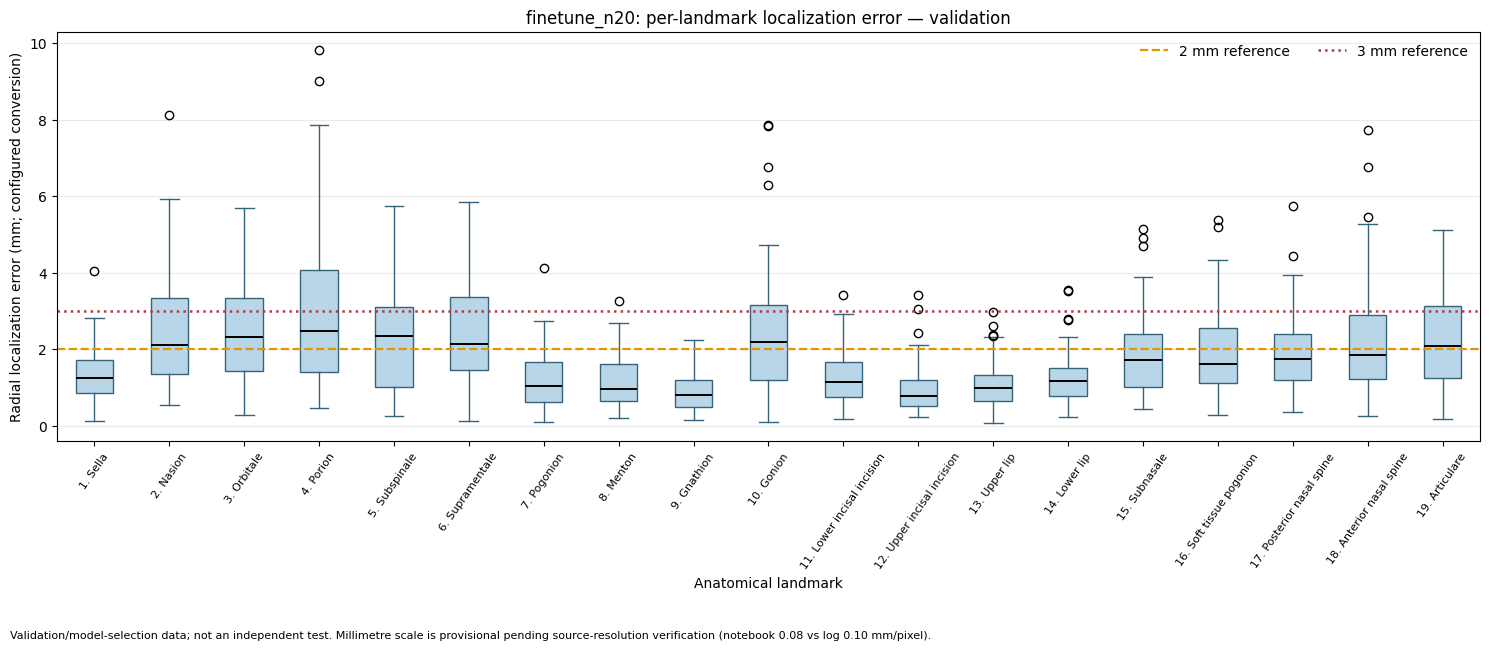

Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_landmark_error_distributions.png
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_landmark_error_distributions.pdf


In [10]:
# Compact, publication-readable per-landmark error distributions.
fig, ax = plt.subplots(figsize=(15, 6.5))
box = ax.boxplot(
    [error_matrix[:, index] for index in range(cfg.num_landmarks)],
    labels=[f'{index + 1}. {LANDMARK_NAMES[index]}' for index in range(cfg.num_landmarks)],
    showfliers=True, patch_artist=True, medianprops={'color': 'black', 'linewidth': 1.4},
    boxprops={'facecolor': '#b9d6e8', 'edgecolor': '#37627c'},
    whiskerprops={'color': '#37627c'}, capprops={'color': '#37627c'},
)
ax.axhline(2.0, color='#e69500', linestyle='--', linewidth=1.6, label='2 mm reference')
ax.axhline(3.0, color='#b23a48', linestyle=':', linewidth=1.8, label='3 mm reference')
ax.set_title(f'{EXPERIMENT_NAME}: per-landmark localization error — validation')
ax.set_xlabel('Anatomical landmark')
ax.set_ylabel('Radial localization error (mm; configured conversion)')
ax.tick_params(axis='x', labelrotation=55, labelsize=8)
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False, ncol=2, loc='upper right')
fig.text(0.01, 0.01, 'Validation/model-selection data; not an independent test. Millimetre scale is provisional pending source-resolution verification (notebook 0.08 vs log 0.10 mm/pixel).', fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
landmark_figure = RESULTS_DIR / f'{RESULTS_STEM}_validation_landmark_error_distributions'
fig.savefig(landmark_figure.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(landmark_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()
print('Saved:', landmark_figure.with_suffix('.png'))
print('Saved:', landmark_figure.with_suffix('.pdf'))


### 6.3 Best, median, and worst radiographs with landmark overlays

The three images are selected by image-level mean radial error on the validation split. Ground-truth landmarks are cyan circles, predicted landmarks are magenta crosses, and yellow connectors show displacement. Landmark labels are anatomical abbreviations where available; the accompanying CSV gives full names and errors. Caption: *Representative best-, median-, and worst-performing validation radiographs under the restored primary checkpoint; examples are descriptive and validation was used in model selection.*

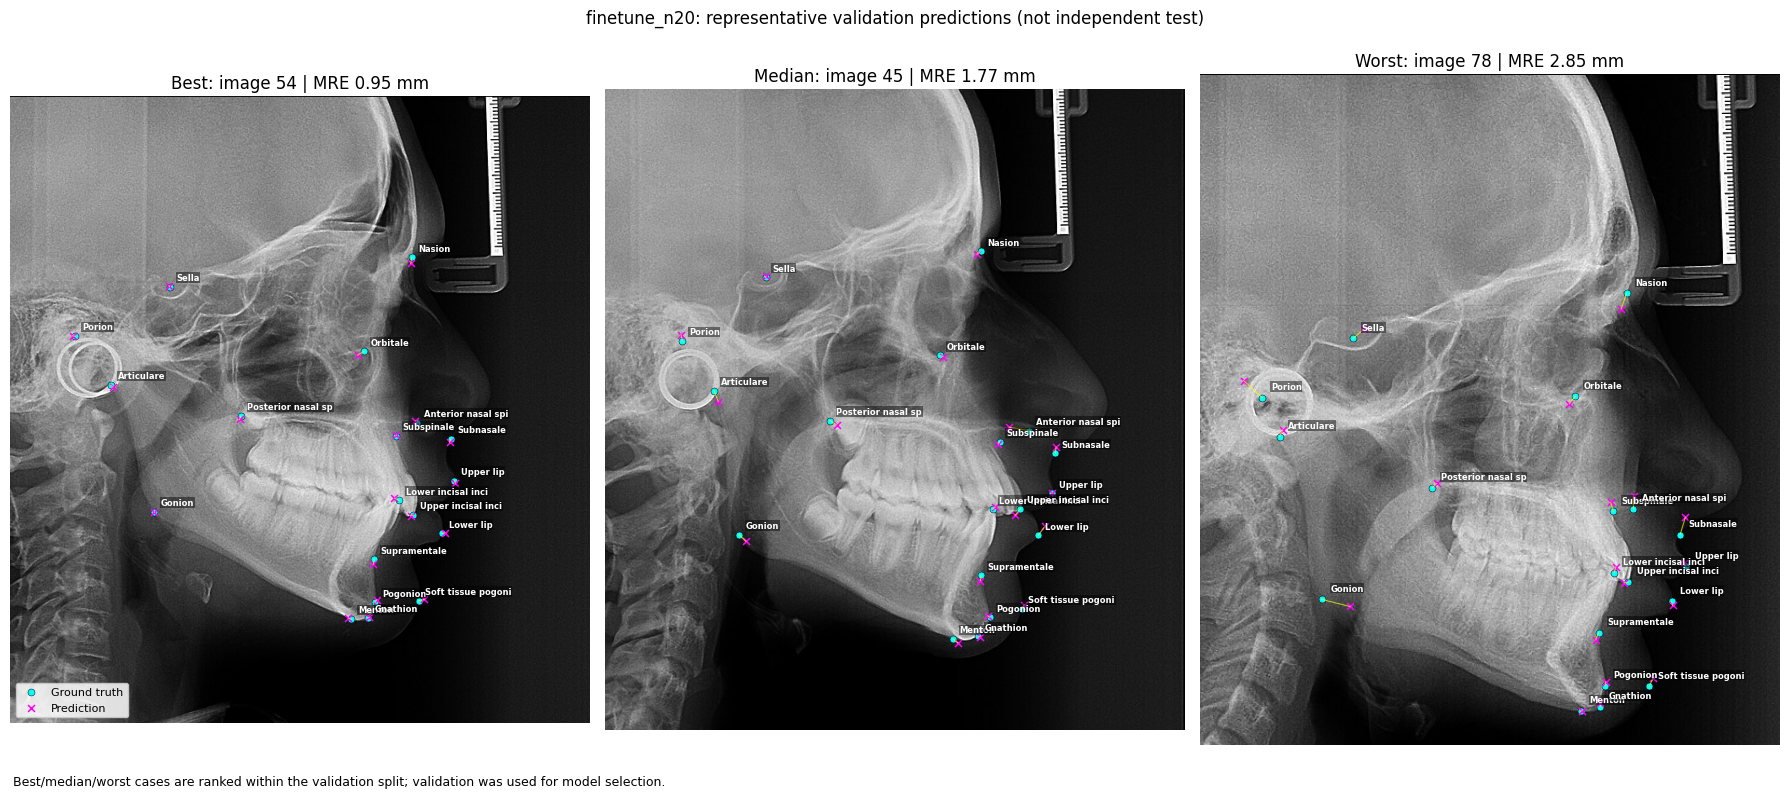

,example,image_id,landmark_index,landmark,error_mm
0,best,54,1,Sella,0.363
1,best,54,2,Nasion,1.864
2,best,54,3,Orbitale,2.053
3,best,54,4,Porion,0.733
4,best,54,5,Subspinale,0.248
5,best,54,6,Supramentale,1.517
6,best,54,7,Pogonion,0.865
7,best,54,8,Menton,0.846
8,best,54,9,Gnathion,0.492
9,best,54,10,Gonion,0.144


Saved: /kaggle/working/results/stage3_v3_finetune_n20_best_median_worst_overlays.png
Saved: /kaggle/working/results/stage3_v3_finetune_n20_best_median_worst_overlays.pdf


In [11]:
def _plot_prediction_overlay(axis, record, title):
    image = record['image']
    truth = record['truth_raw']
    prediction = record['pred_raw']
    axis.imshow(image, cmap='gray')
    for index, (truth_point, prediction_point) in enumerate(zip(truth, prediction)):
        axis.plot(
            [truth_point[0], prediction_point[0]],
            [truth_point[1], prediction_point[1]],
            color='yellow', linewidth=0.8, alpha=0.65,
        )
    axis.scatter(truth[:, 0], truth[:, 1], s=25, c='cyan', edgecolors='black', linewidths=0.35, label='Ground truth')
    axis.scatter(prediction[:, 0], prediction[:, 1], s=25, c='magenta', marker='x', linewidths=1.1, label='Prediction')
    for index, (x, y) in enumerate(truth):
        short_name = LANDMARK_NAMES[index].replace('_', ' ')[:18]
        axis.text(x + 8, y - 8, short_name, color='white', fontsize=6, weight='bold',
                  bbox={'facecolor': 'black', 'alpha': 0.45, 'pad': 0.5, 'linewidth': 0})
    axis.set_title(f"{title}: image {record['image_id']} | MRE {record['mre_mm']:.2f} mm")
    axis.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for axis, (label, record) in zip(axes, example_records.items()):
    _plot_prediction_overlay(axis, record, label.capitalize())
axes[0].legend(loc='lower left', fontsize=8, framealpha=0.85)
fig.suptitle(f'{EXPERIMENT_NAME}: representative validation predictions (not independent test)', y=0.98)
fig.text(0.01, 0.01, 'Best/median/worst cases are ranked within the validation split; validation was used for model selection.', fontsize=9)
fig.tight_layout()
overlay_figure = RESULTS_DIR / f'{RESULTS_STEM}_best_median_worst_overlays'
fig.savefig(overlay_figure.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(overlay_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()

selected_display = selected_landmark_table.copy()
selected_display['error_mm'] = selected_display['error_mm'].round(3)
display(selected_display)
print('Saved:', overlay_figure.with_suffix('.png'))
print('Saved:', overlay_figure.with_suffix('.pdf'))


### 6.4 Spatial localization heatmap overlaid on the radiograph

The figure overlays the maximum predicted landmark probability projection directly on the median-error validation radiograph and retains the ground-truth and predicted coordinates. The probability overlay is a qualitative model-localization visualization, not an uncertainty-calibrated clinical measure. Caption: *Maximum spatial probability projection over the median-error validation radiograph; cyan marks annotated landmarks and magenta marks model predictions. The colour overlay visualizes model response and should not be interpreted as clinical confidence.*

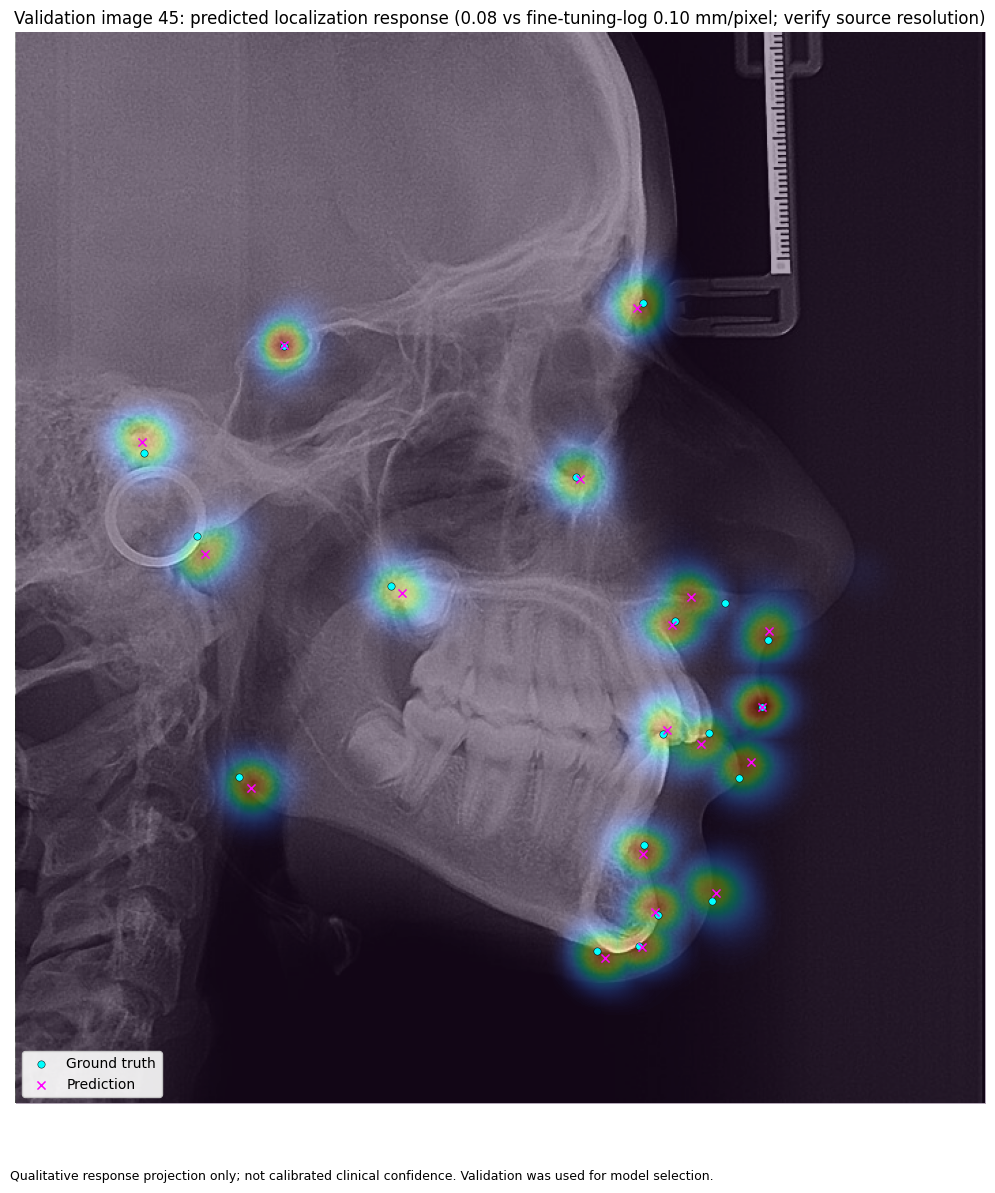

Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_median_spatial_response_overlay.png
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_median_spatial_response_overlay.pdf


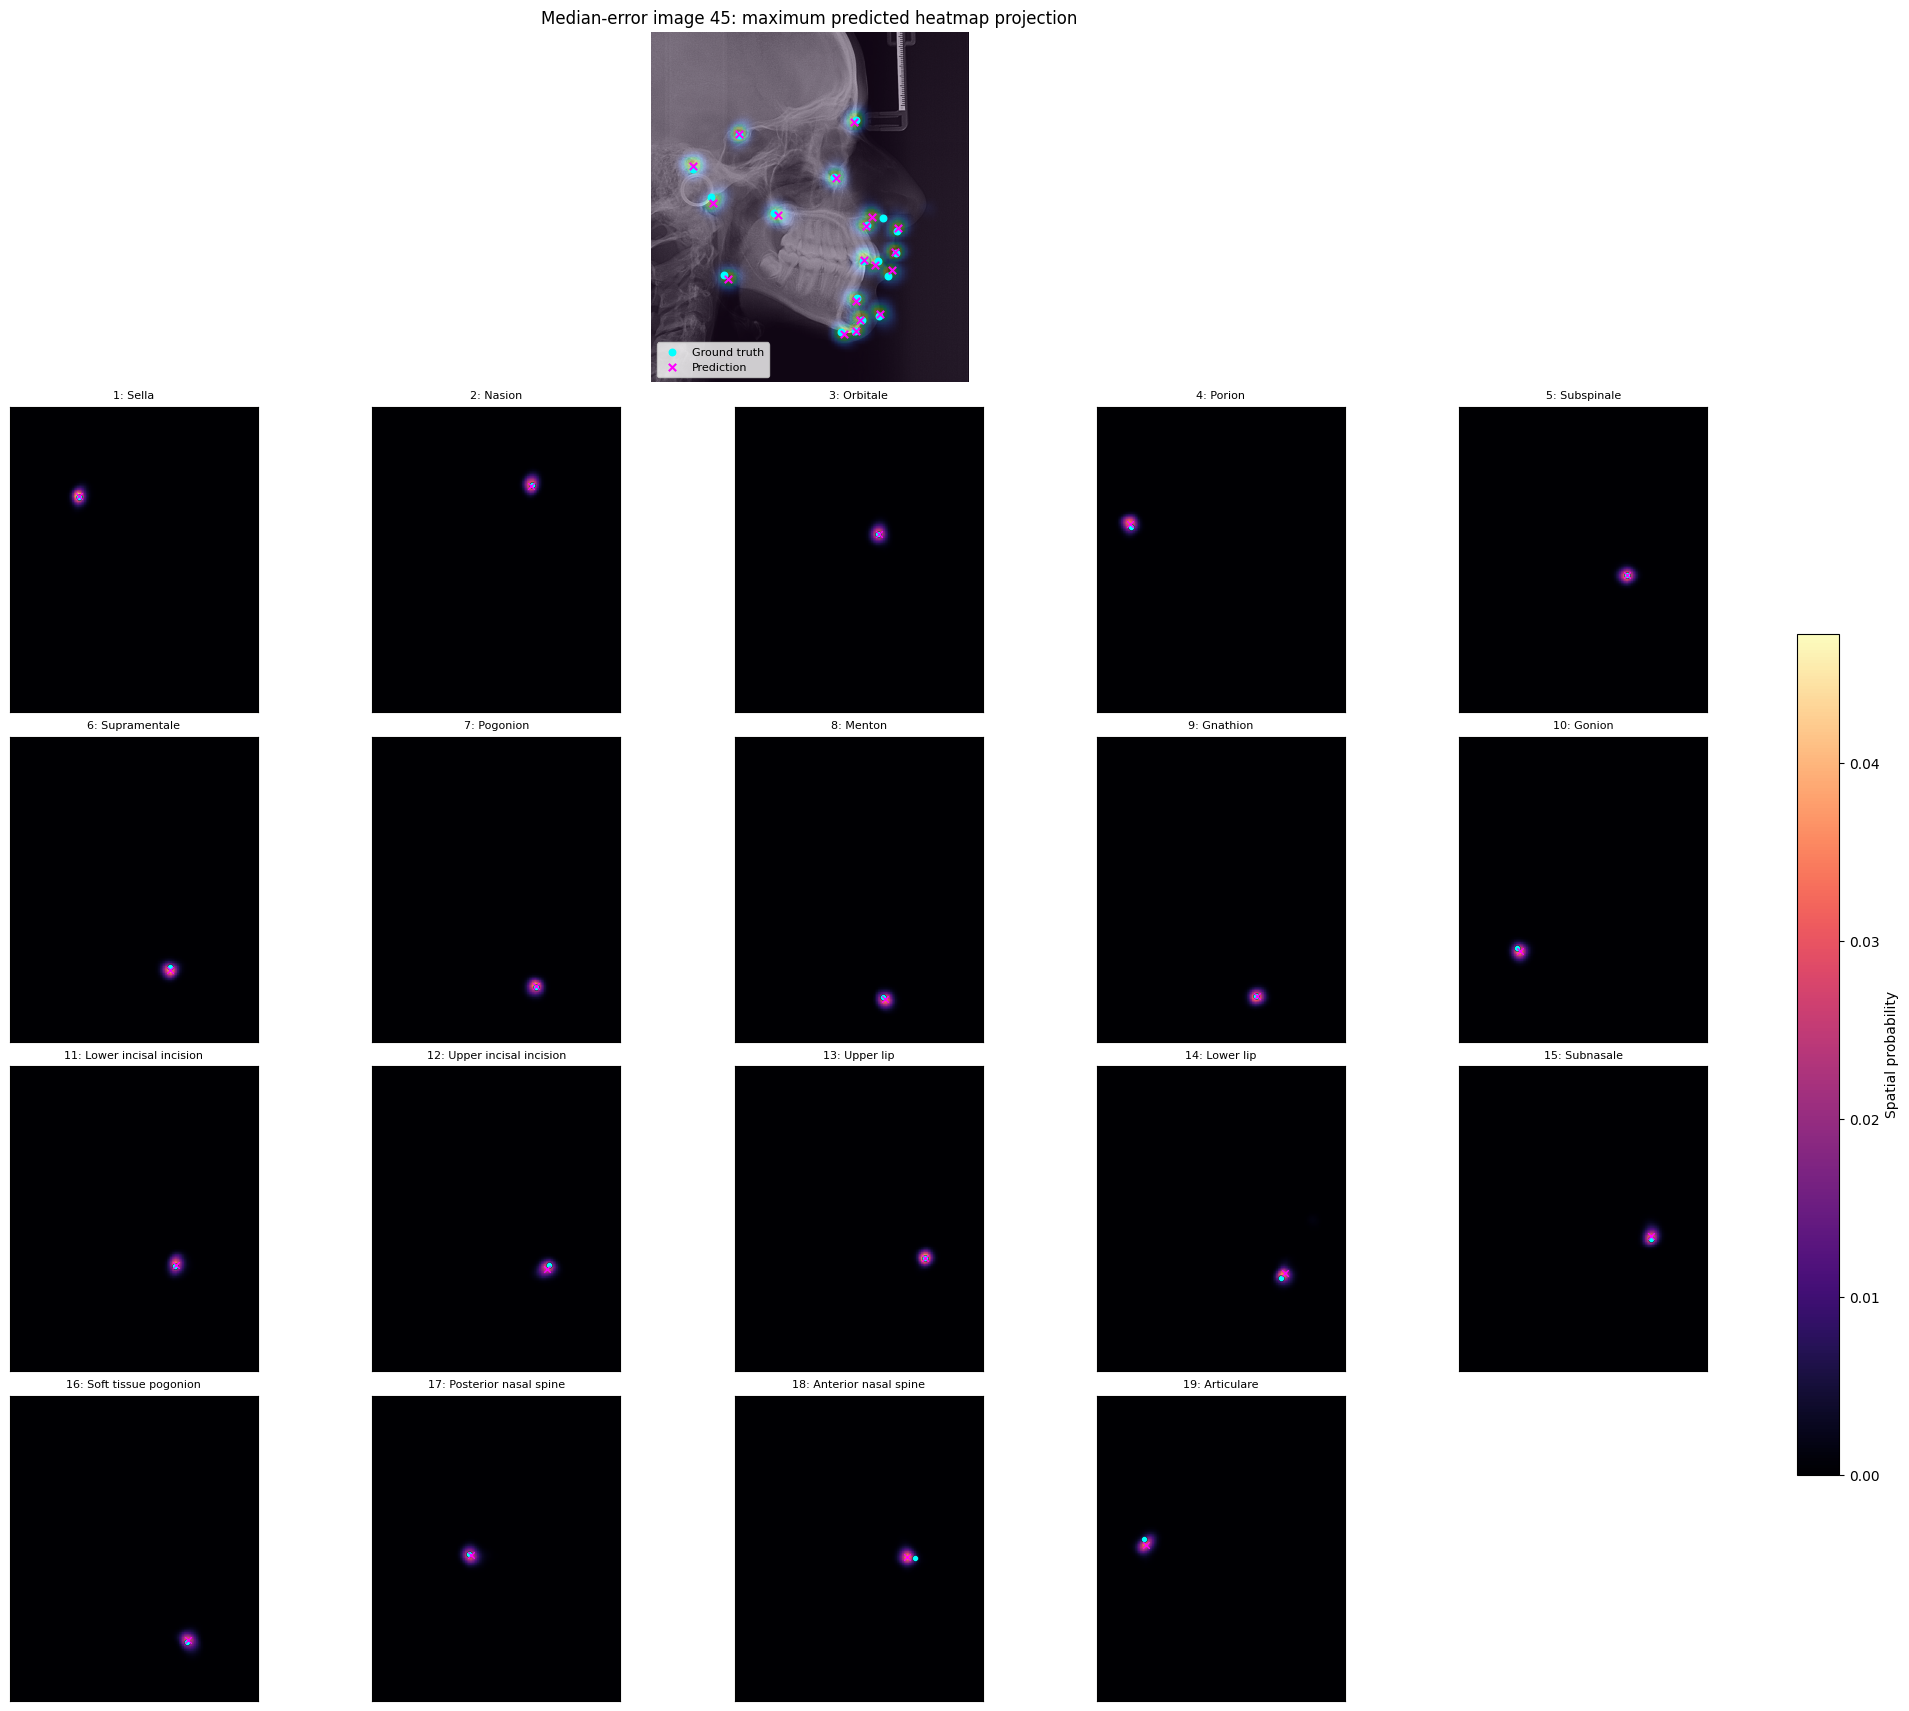

Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_median_per_landmark_heatmap_diagnostic_grid.png
Saved: /kaggle/working/results/stage3_v3_finetune_n20_validation_median_per_landmark_heatmap_diagnostic_grid.pdf


In [12]:
# Direct radiograph-overlay figure intended for clinical visual inspection.
heatmap_record = example_records['median']
heatmaps = heatmap_record['heatmaps']
max_projection = np.max(heatmaps, axis=-1)
image_height, image_width = heatmap_record['image'].shape[:2]
fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(heatmap_record['image'], cmap='gray')
ax.imshow(
    max_projection, cmap='turbo', alpha=0.38,
    extent=(0, image_width, image_height, 0), interpolation='bilinear',
)
ax.scatter(heatmap_record['truth_raw'][:, 0], heatmap_record['truth_raw'][:, 1],
           c='cyan', edgecolors='black', linewidths=0.35, s=28, label='Ground truth')
ax.scatter(heatmap_record['pred_raw'][:, 0], heatmap_record['pred_raw'][:, 1],
           c='magenta', marker='x', linewidths=1.1, s=34, label='Prediction')
ax.set_title(f"Validation image {heatmap_record['image_id']}: predicted localization response (0.08 vs fine-tuning-log 0.10 mm/pixel; verify source resolution)")
ax.axis('off')
ax.legend(loc='lower left', framealpha=0.9)
fig.text(0.01, 0.01, 'Qualitative response projection only; not calibrated clinical confidence. Validation was used for model selection.', fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
heatmap_overlay_figure = RESULTS_DIR / f'{RESULTS_STEM}_validation_median_spatial_response_overlay'
fig.savefig(heatmap_overlay_figure.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(heatmap_overlay_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()
print('Saved:', heatmap_overlay_figure.with_suffix('.png'))
print('Saved:', heatmap_overlay_figure.with_suffix('.pdf'))

heatmaps = heatmap_record['heatmaps']
heatmap_height, heatmap_width = heatmaps.shape[:2]
truth_hm = heatmap_record['truth_norm'] * np.array([heatmap_width - 1, heatmap_height - 1], dtype=np.float32)
pred_hm = heatmap_record['pred_norm'] * np.array([heatmap_width - 1, heatmap_height - 1], dtype=np.float32)

fig = plt.figure(figsize=(20, 17), constrained_layout=True)
grid = fig.add_gridspec(5, 5, height_ratios=[1.15, 1, 1, 1, 1])
ax_overlay = fig.add_subplot(grid[0, :])
ax_overlay.imshow(heatmap_record['image'], cmap='gray')
max_projection = np.max(heatmaps, axis=-1)
ax_overlay.imshow(max_projection, cmap='turbo', alpha=0.35, extent=(0, heatmap_record['image'].shape[1], heatmap_record['image'].shape[0], 0))
ax_overlay.scatter(heatmap_record['truth_raw'][:, 0], heatmap_record['truth_raw'][:, 1], c='cyan', s=22, label='Ground truth')
ax_overlay.scatter(heatmap_record['pred_raw'][:, 0], heatmap_record['pred_raw'][:, 1], c='magenta', marker='x', s=28, label='Prediction')
ax_overlay.set_title(f"Median-error image {heatmap_record['image_id']}: maximum predicted heatmap projection")
ax_overlay.axis('off')
ax_overlay.legend(loc='lower left', fontsize=8)

heatmap_axes = []
for index in range(cfg.num_landmarks):
    axis = fig.add_subplot(grid[1 + index // 5, index % 5])
    heatmap_axes.append(axis)
    image = axis.imshow(heatmaps[:, :, index], cmap='magma', vmin=0, vmax=float(np.max(heatmaps)))
    axis.scatter(truth_hm[index, 0], truth_hm[index, 1], c='cyan', s=18, edgecolors='black', linewidths=0.3)
    axis.scatter(pred_hm[index, 0], pred_hm[index, 1], c='magenta', marker='x', s=22, linewidths=1)
    axis.set_title(f'{index + 1}: {LANDMARK_NAMES[index]}', fontsize=8)
    axis.set_xticks([])
    axis.set_yticks([])
fig.colorbar(image, ax=heatmap_axes, shrink=0.65, label='Spatial probability')
heatmap_figure = RESULTS_DIR / f'{RESULTS_STEM}_validation_median_per_landmark_heatmap_diagnostic_grid'
fig.savefig(heatmap_figure.with_suffix('.png'), dpi=220, bbox_inches='tight')
fig.savefig(heatmap_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()
print('Saved:', heatmap_figure.with_suffix('.png'))
print('Saved:', heatmap_figure.with_suffix('.pdf'))


### 6.5 Before/after adaptation comparison and editable exports

Before-adaptation values come from the training history's Stage-2 baseline evaluated on the existing validation loader; after-adaptation values come from the restored primary best-validation-loss checkpoint on that same loader. This is a paired model comparison on validation/model-selection data, **not** an independent test evaluation. Paired landmark means are shown by anatomical label, with landmarks remaining above 3 mm after adaptation emphasized. SDR thresholds use the configured metric conversion; because the notebook says 0.08 mm/pixel while the fine-tuning log says 0.10 mm/pixel, verify source resolution before making clinical threshold claims. The raw CSV/JSON exports preserve all available per-image/per-landmark coordinates and threshold indicators.


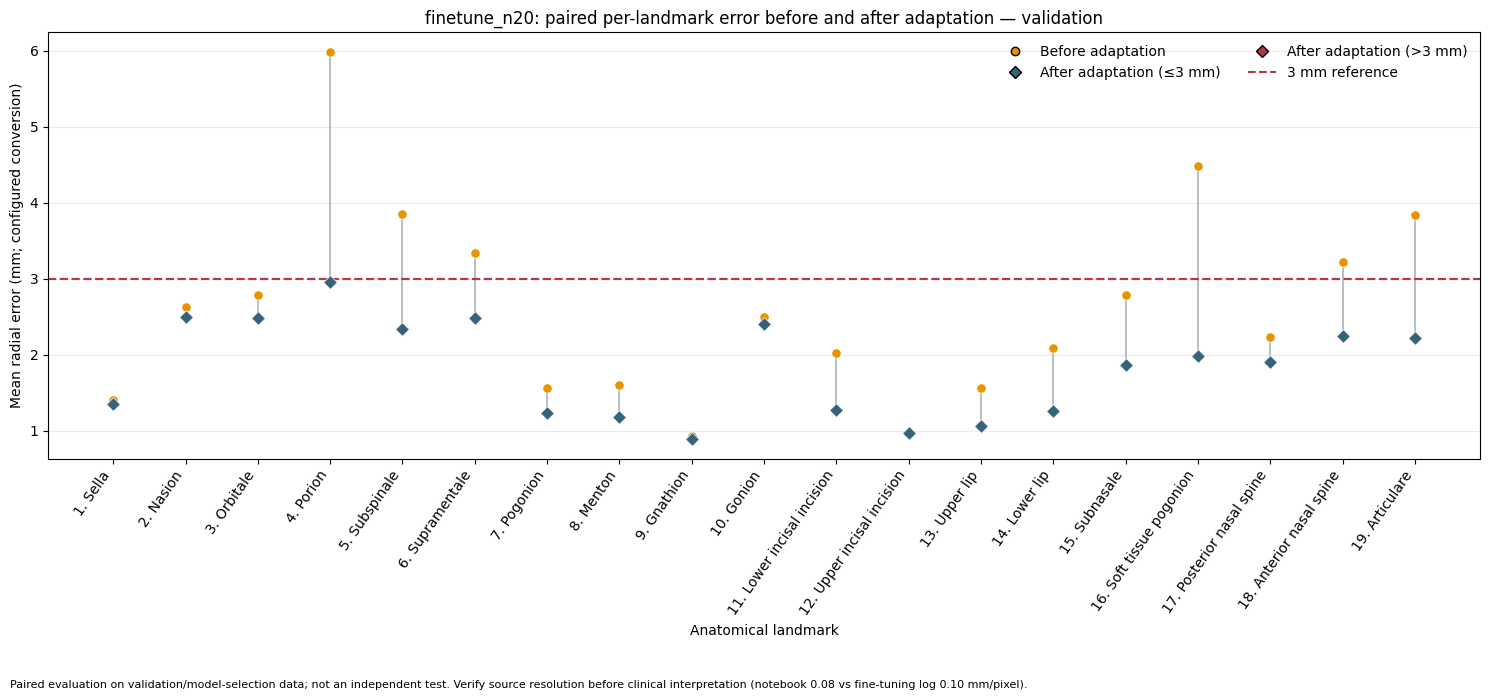

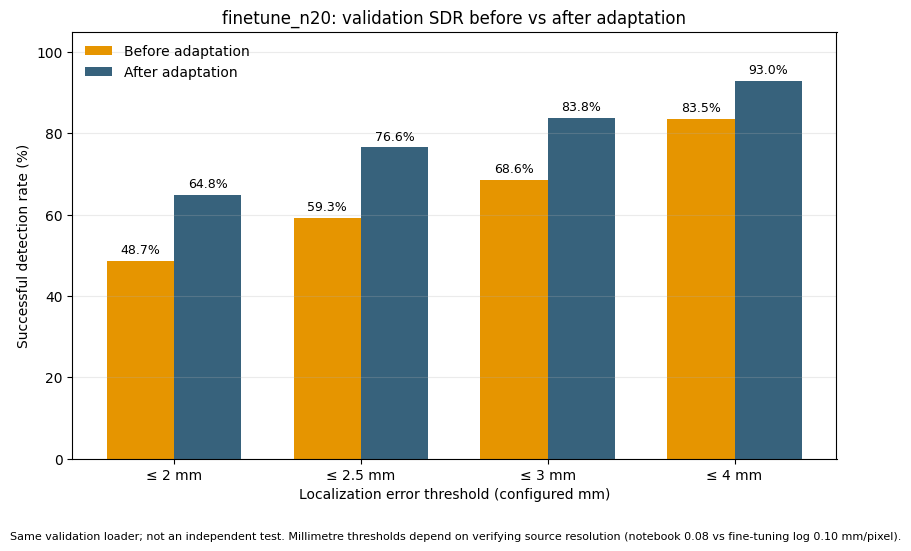

Saved editable figure data and comparisons to /kaggle/working/results


In [13]:
# Paired baseline/fine-tuned metrics and thesis figures; no new inference/training is performed.
import pandas as pd

before_landmark = np.asarray(history['baseline']['per_landmark_mre'], dtype=float)
after_landmark = np.asarray(primary_metrics['per_landmark_mre'], dtype=float)
if before_landmark.shape[0] != cfg.num_landmarks or after_landmark.shape[0] != cfg.num_landmarks:
    raise ValueError('Per-landmark baseline/primary metric length does not match configured landmarks.')
landmark_comparison = pd.DataFrame({
    'landmark_index': np.arange(1, cfg.num_landmarks + 1),
    'landmark_name': LANDMARK_NAMES,
    'before_adaptation_mre_mm_configured': before_landmark,
    'after_adaptation_mre_mm_configured': after_landmark,
})
landmark_comparison['change_mm_configured'] = (
    landmark_comparison['after_adaptation_mre_mm_configured']
    - landmark_comparison['before_adaptation_mre_mm_configured']
)
landmark_comparison['after_remains_over_3mm_configured'] = (
    landmark_comparison['after_adaptation_mre_mm_configured'] > 3.0
)
landmark_comparison['resolution_mm_per_px_configured'] = float(cfg.image_resolution)
landmark_comparison.to_csv(RESULTS_DIR / f'{RESULTS_STEM}_validation_before_after_per_landmark.csv', index=False)

aggregate_rows = []
for stage, metrics in [('before_adaptation_stage2_baseline', history['baseline']),
                       ('after_adaptation_primary_best_validation_loss', primary_metrics)]:
    aggregate_rows.append({
        'stage': stage,
        'evaluation_split': 'validation',
        'overall_mre_mm_configured': float(metrics['mre']),
        'resolution_mm_per_px_configured': float(cfg.image_resolution),
        **{f'sdr_{str(float(k)).replace(".", "_")}mm_percent': float(v)
           for k, v in metrics['sdr'].items()},
    })
aggregate_comparison = pd.DataFrame(aggregate_rows)
aggregate_comparison.to_csv(RESULTS_DIR / f'{RESULTS_STEM}_validation_before_after_aggregate_metrics.csv', index=False)

# Include an aligned per-image comparison only if the saved history exposes compatible raw baseline predictions.
# Current history retains aggregate baseline metrics, not baseline per-image coordinates; no values are synthesized.

fig, ax = plt.subplots(figsize=(15, 7))
x = np.arange(cfg.num_landmarks)
for index, row in landmark_comparison.iterrows():
    color = '#b23a48' if row['after_remains_over_3mm_configured'] else '#37627c'
    ax.plot([x[index], x[index]], [row['before_adaptation_mre_mm_configured'], row['after_adaptation_mre_mm_configured']],
            color='#aab4bc', linewidth=1.2, zorder=1)
    ax.scatter(x[index], row['before_adaptation_mre_mm_configured'], marker='o', s=45,
               color='#e69500', edgecolor='white', linewidth=0.5, zorder=2)
    ax.scatter(x[index], row['after_adaptation_mre_mm_configured'], marker='D', s=48,
               color=color, edgecolor='white', linewidth=0.5, zorder=3)
ax.axhline(3.0, color='#b23a48', linestyle='--', linewidth=1.6, label='3 mm reference')
ax.set_xticks(x, [f'{i+1}. {name}' for i, name in enumerate(LANDMARK_NAMES)], rotation=55, ha='right')
ax.set_ylabel('Mean radial error (mm; configured conversion)')
ax.set_xlabel('Anatomical landmark')
ax.set_title(f'{EXPERIMENT_NAME}: paired per-landmark error before and after adaptation — validation')
ax.grid(axis='y', alpha=0.25)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], marker='o', color='none', markerfacecolor='#e69500', label='Before adaptation'),
                   Line2D([0], [0], marker='D', color='none', markerfacecolor='#37627c', label='After adaptation (≤3 mm)'),
                   Line2D([0], [0], marker='D', color='none', markerfacecolor='#b23a48', label='After adaptation (>3 mm)'),
                   Line2D([0], [0], color='#b23a48', linestyle='--', label='3 mm reference')],
          frameon=False, ncol=2, loc='upper right')
fig.text(0.01, 0.01, 'Paired evaluation on validation/model-selection data; not an independent test. Verify source resolution before clinical interpretation (notebook 0.08 vs fine-tuning log 0.10 mm/pixel).', fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
paired_figure = RESULTS_DIR / f'{RESULTS_STEM}_validation_paired_before_after_landmark_mre'
fig.savefig(paired_figure.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(paired_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()

# Compare aggregate SDR at the requested cut-offs using baseline and primary metrics.
sdr_cutoffs = [2.0, 2.5, 3.0, 4.0]
def _metric_for_threshold(metric_dict, threshold):
    for key, value in metric_dict.items():
        if np.isclose(float(key), threshold):
            return float(value)
    return float('nan')

sdr_rows = []
for threshold in sdr_cutoffs:
    sdr_rows.append({
        'threshold_mm_configured': threshold,
        'before_adaptation_percent': _metric_for_threshold(history['baseline']['sdr'], threshold),
        'after_adaptation_percent': _metric_for_threshold(primary_metrics['sdr'], threshold),
    })
sdr_comparison = pd.DataFrame(sdr_rows)
sdr_comparison.to_csv(RESULTS_DIR / f'{RESULTS_STEM}_validation_before_after_sdr.csv', index=False)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
x = np.arange(len(sdr_cutoffs))
width = 0.36
bars_before = ax.bar(x - width/2, sdr_comparison['before_adaptation_percent'], width, label='Before adaptation', color='#e69500')
bars_after = ax.bar(x + width/2, sdr_comparison['after_adaptation_percent'], width, label='After adaptation', color='#37627c')
ax.bar_label(bars_before, fmt='%.1f%%', padding=3, fontsize=9)
ax.bar_label(bars_after, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_xticks(x, [f'≤ {t:g} mm' for t in sdr_cutoffs])
ax.set_ylim(0, max(100, np.nanmax(sdr_comparison[['before_adaptation_percent', 'after_adaptation_percent']].to_numpy()) + 12))
ax.set_ylabel('Successful detection rate (%)')
ax.set_xlabel('Localization error threshold (configured mm)')
ax.set_title(f'{EXPERIMENT_NAME}: validation SDR before vs after adaptation')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
fig.text(0.01, 0.01, 'Same validation loader; not an independent test. Millimetre thresholds depend on verifying source resolution (notebook 0.08 vs fine-tuning log 0.10 mm/pixel).', fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
sdr_figure = RESULTS_DIR / f'{RESULTS_STEM}_validation_before_after_sdr'
fig.savefig(sdr_figure.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(sdr_figure.with_suffix('.pdf'), bbox_inches='tight')
plt.show()

# Editable raw values used by figures (aggregate, per-landmark distributions, and paired metrics).
aggregate_long = pd.DataFrame([
    {'stage': stage, 'landmark_index': i + 1, 'landmark_name': LANDMARK_NAMES[i], 'mre_mm_configured': float(values[i]),
     'evaluation_split': 'validation', 'resolution_mm_per_px_configured': float(cfg.image_resolution)}
    for stage, values in [('before_adaptation_stage2_baseline', before_landmark),
                          ('after_adaptation_primary_best_validation_loss', after_landmark)]
    for i in range(cfg.num_landmarks)
])
aggregate_long.to_csv(RESULTS_DIR / f'{RESULTS_STEM}_validation_before_after_landmark_metrics_long.csv', index=False)
error_distribution_rows = [
    {'image_id': int(record['image_id']), 'landmark_index': index + 1,
     'landmark_name': LANDMARK_NAMES[index], 'error_px_reference': float(record['error_px_reference'][index]),
     'error_mm_configured': float(record['error_mm'][index]),
     **{f'pass_{str(t).replace(".", "_")}mm_configured': bool(record['error_mm'][index] < t) for t in thresholds}}
    for record in records for index in range(cfg.num_landmarks)
]
error_distribution_table = pd.DataFrame(error_distribution_rows)
error_distribution_table.to_csv(RESULTS_DIR / f'{RESULTS_STEM}_validation_per_landmark_error_distributions_long.csv', index=False)

raw_export_json = {
    'evaluation_split': 'validation',
    'independent_test_status': 'not established; validation was used for model selection and monitoring',
    'resolution_mm_per_pixel_notebook_configured': float(cfg.image_resolution),
    'resolution_mm_per_pixel_finetuning_log': 0.10,
    'resolution_discrepancy_warning': 'Verify source resolution before clinical interpretation of millimetre errors/thresholds.',
    'aggregate_metrics_before_after': aggregate_rows,
    'sdr_before_after': sdr_rows,
    'per_landmark_before_after': landmark_comparison.to_dict(orient='records'),
    'per_image_per_landmark_coordinates_errors': coordinate_rows,
}
raw_json = RESULTS_DIR / f'{RESULTS_STEM}_validation_editable_figure_data.json'
raw_json.write_text(json.dumps(raw_export_json, indent=2), encoding='utf-8')
print('Saved editable figure data and comparisons to', RESULTS_DIR)


### 6.6 Paper-ready reporting block

Use exported CSV, JSON, PNG and PDF artifacts together with the fixed experiment metadata. Quantitative comparisons are validation/model-selection results and are not an independent test estimate. Millimetre interpretations require resolution verification.


In [14]:
# A final compact block that can be copied into a Results/Discussion draft.
worst_landmark_row = landmark_table.iloc[int(np.argmax(landmark_table['mean_error_mm']))]
print(
    f"Stage 3 ({EXPERIMENT_NAME}) adapted the model using {len(TRAIN_IMAGE_IDS)} training images "
    f"and evaluated {len(VAL_IMAGE_IDS)} validation images. The primary restored checkpoint "
    f"achieved an overall MRE of {primary_metrics['mre']:.3f} mm. Image-level MRE was "
    f"{mean_image_mre:.3f} ± {std_image_mre:.3f} mm (median {median_image_mre:.3f} mm). "
    f"The most difficult landmark by mean radial error was landmark "
    f"{int(worst_landmark_row['landmark_index'])} ({worst_landmark_row['landmark']}), "
    f"at {worst_landmark_row['mean_error_mm']:.3f} mm."
)
print('Artifacts are in:', RESULTS_DIR)
print('  -', per_image_csv.name)
print('  -', landmark_csv.name)
print('  -', selected_csv.name)
print('  -', summary_json.name)


Stage 3 (finetune_n20) adapted the model using 20 training images and evaluated 60 validation images. The primary restored checkpoint achieved an overall MRE of 1.819 mm. Image-level MRE was 1.819 ± 0.323 mm (median 1.766 mm). The most difficult landmark by mean radial error was landmark 4 (Porion), at 2.961 mm.
Artifacts are in: /kaggle/working/results
  - stage3_v3_finetune_n20_validation_per_image_metrics.csv
  - stage3_v3_finetune_n20_validation_landmark_metrics.csv
  - stage3_v3_finetune_n20_selected_examples_landmark_errors.csv
  - stage3_v3_finetune_n20_results_summary.json


In [15]:
print("Configured reference size:")
print("width:", cfg.original_width)
print("height:", cfg.original_height)
print("resolution:", cfg.image_resolution, "mm/pixel")

for record in records[:5]:
    image = record["image"]
    print(
        "Image", record["image_id"],
        "raw size:", (image.shape[1], image.shape[0]),
        "reference size:", (cfg.original_width, cfg.original_height),
    )


Configured reference size:
width: 1935
height: 2400
resolution: 0.08 mm/pixel
Image 1 raw size: (1067, 1175) reference size: (1935, 2400)
Image 2 raw size: (549, 582) reference size: (1935, 2400)
Image 3 raw size: (515, 576) reference size: (1935, 2400)
Image 4 raw size: (553, 622) reference size: (1935, 2400)
Image 6 raw size: (516, 593) reference size: (1935, 2400)


In [16]:
record = example_records["median"]
landmark_index = 0

pred_norm = record["pred_norm"][landmark_index]
true_norm = record["truth_norm"][landmark_index]

raw_delta = (
    record["pred_raw"][landmark_index]
    - record["truth_raw"][landmark_index]
)

reference_delta = (
    (pred_norm - true_norm)
    * np.array([cfg.original_width, cfg.original_height])
)

raw_pixel_distance = np.linalg.norm(raw_delta)
reference_pixel_distance = np.linalg.norm(reference_delta)
error_mm = reference_pixel_distance * cfg.image_resolution

print("Raw-image pixel distance:", raw_pixel_distance)
print("Reference pixel distance:", reference_pixel_distance)
print("Metric error:", error_mm, "mm")


Raw-image pixel distance: 1.0032909
Reference pixel distance: 3.058865105391843
Metric error: 0.24470920843134747 mm


In [17]:
record = example_records["median"]
landmark_index = 0

pred_norm = record["pred_norm"][landmark_index]
true_norm = record["truth_norm"][landmark_index]

raw_delta = (
    record["pred_raw"][landmark_index]
    - record["truth_raw"][landmark_index]
)

reference_delta = (
    (pred_norm - true_norm)
    * np.array([cfg.original_width, cfg.original_height])
)

raw_pixel_distance = np.linalg.norm(raw_delta)
reference_pixel_distance = np.linalg.norm(reference_delta)
error_mm = reference_pixel_distance * cfg.image_resolution

print("Raw image size:", record["image"].shape[1], "×", record["image"].shape[0])
print("Raw-image pixel distance:", raw_pixel_distance)
print("Reference-coordinate pixel distance:", reference_pixel_distance)
print("MRE for this landmark:", error_mm, "mm")


Raw image size: 712 × 787
Raw-image pixel distance: 1.0032909
Reference-coordinate pixel distance: 3.058865105391843
MRE for this landmark: 0.24470920843134747 mm
